In [1]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
students = pd.read_csv("students_100.csv")
print(students.shape)

x = torch.tensor(
    students[["study_hours", "phone_hours"]].values,
    dtype=torch.float32
)
y = torch.tensor(students["maths"].values, dtype=torch.float32)
print(x.shape)
print(y.shape)

(100, 8)
torch.Size([100, 2])
torch.Size([100])


In [15]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 1),
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)

In [16]:
losses = []
for epoch in range(300):
    guess = model(x)
    loss = loss_fn(guess, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 50 == 0:
        print(f"epoch {epoch:3}: loss = {loss.item():.1f}")

epoch   0: loss = 3023.5
epoch  50: loss = 282.8
epoch 100: loss = 268.6
epoch 150: loss = 253.4
epoch 200: loss = 237.5
epoch 250: loss = 220.7


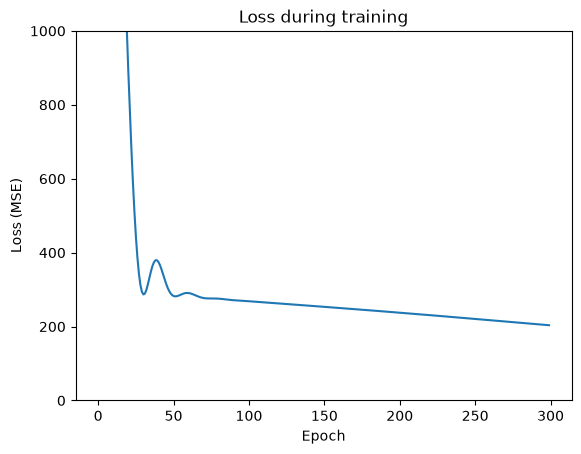

In [17]:
plt.plot(losses)
plt.ylim(0, 1000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

In [18]:
with torch.no_grad():
    new_student = torch.tensor([[3, 2]], dtype=torch.float32)
    print("3 study hours, 2 phone hours ->", round(model(new_student).item(), 1), "marks")

3 study hours, 2 phone hours -> 46.9 marks
